<a href="https://colab.research.google.com/github/mshitie/quantitative_XAI/blob/main/quantitative_XAI_evaluation_BUSI_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantitative XAI on BUSI Breast Ultrasound (ResNet50 / DenseNet121 / VGG16)

**Task:** 3-class classification (benign / malignant / normal) + quantitative evaluation of explanations.

**XAI methods:** Grad-CAM, Grad-CAM++, LayerCAM, Integrated Gradients, RISE, plus two sanity baselines (random smooth map, centre prior).

**Metrics**
- *Faithfulness:* Deletion AUC (lower = better), Insertion AUC (higher), Average Drop % (lower), Increase in Confidence % (higher)
- *Localization* (benign/malignant only, normal images have empty masks): lesion energy, **relative energy** (energy / lesion area, 1 = chance), rank accuracy, pointing game, IoU@0.5, **map AUROC** (threshold-free, 0.5 = chance)
- *Stability:* Spearman correlation of maps under small Gaussian noise
- *Sanity check:* model-parameter randomization test (Adebayo et al., 2018)

**What is new compared with the previous notebook**
1. Near-duplicate detection (dHash) and a **group-aware stratified split**, so duplicates cannot leak between train and test
2. Configurable backbone (`BACKBONE`), so the same pipeline runs for several models
3. Explanations computed on **logits** (no softmax saturation), plus Grad-CAM++, LayerCAM, RISE and a centre-prior baseline
4. New localization metrics (relative energy, map AUROC) that are comparable across lesion sizes
5. Evaluation on **all** test images, with **bootstrap 95% CIs** and **paired Wilcoxon tests (Holm-corrected)**
6. Correct-vs-incorrect analysis, metric-agreement analysis, parameter-randomization sanity check
7. Bootstrap CIs on classification metrics; outputs are named per backbone so runs can be compared
8. **Revision:** robust Kaggle setup, listing of label-conflicting duplicate groups, **cluster (group-level) bootstrap** for XAI CIs, and reporting of the fraction of noisy copies kept in the stability metric

In [1]:
!pip install -q kaggle
import os
if not os.path.exists('/content/kaggle.json'):
    # Option A: pick kaggle.json in the file dialog. Option B: drag it into the Files sidebar,
    # or copy it from Drive with: !cp /content/drive/MyDrive/<your path>/kaggle.json /content/kaggle.json
    from google.colab import files
    files.upload()
assert os.path.exists('/content/kaggle.json'), "kaggle.json still not found in /content"
os.environ['KAGGLE_CONFIG_DIR'] = '/content'
!chmod 600 /content/kaggle.json
!kaggle datasets download -d aryashah2k/breast-ultrasound-images-dataset
!unzip -q breast-ultrasound-images-dataset.zip -d busi

Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/aryashah2k/breast-ultrasound-images-dataset
License(s): CC0-1.0
100% 195M/195M [00:01<00:00, 161MB/s]



In [2]:
import os, glob, random, warnings, time
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import ResNet50, DenseNet121, VGG16
from tensorflow.keras.applications import resnet50, densenet, vgg16
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, auc,
                             accuracy_score, f1_score)
from sklearn.utils.class_weight import compute_class_weight
from scipy.stats import spearmanr, wilcoxon

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ------------------------------- CONFIG -------------------------------
BACKBONE = "resnet50"            # "resnet50" | "densenet121" | "vgg16"
DATA_DIR = "/content/busi/Dataset_BUSI_with_GT"   # contains benign/ malignant/ normal/
CLASSES = ["benign", "malignant", "normal"]
IMG_SIZE, BATCH = 224, 32
MAX_PER_CLASS = None             # e.g. 150 for a quick smoke test
N_EVAL_PER_CLASS = None          # None = evaluate XAI on EVERY test image
N_NOISE = 5                      # noisy copies per image for the stability metric
N_BOOT = 2000                    # bootstrap resamples for confidence intervals
USE_RISE, N_RISE = True, 500     # RISE is slow: set USE_RISE=False for a fast run
N_SANITY = 30                    # images for the parameter-randomization test
DUP_HAMMING = 6                  # dHash Hamming distance (of 256 bits) treated as duplicate

BACKBONES = {
    "resnet50":    dict(cls=ResNet50,    prep=resnet50.preprocess_input,    last_conv="conv5_block3_out", unfreeze="conv5"),
    "densenet121": dict(cls=DenseNet121, prep=densenet.preprocess_input, last_conv="relu",             unfreeze="conv5"),
    "vgg16":       dict(cls=VGG16,       prep=vgg16.preprocess_input,       last_conv="block5_conv3",     unfreeze="block5"),
}
CFG = BACKBONES[BACKBONE]
preprocess_input = CFG["prep"]
OUT = f"xai_{BACKBONE}"          # prefix of every file written by this notebook

# Neutral-gray image in the model's input space (XAI baseline / 'deleted pixel' value) and the
# input-space change per +1 raw pixel level (used to scale noise in the stability test).
GRAY = preprocess_input(np.full((IMG_SIZE, IMG_SIZE, 3), 127.5, "float32"))
SCALE = preprocess_input(np.full((IMG_SIZE, IMG_SIZE, 3), 128.5, "float32")) - GRAY
print("Backbone:", BACKBONE, "| GPU:", tf.config.list_physical_devices("GPU"))

Backbone: resnet50 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
rows = []
for c in CLASSES:
    for p in sorted(glob.glob(os.path.join(DATA_DIR, c, "*.png"))):
        if "_mask" in os.path.basename(p):          # masks live in the same folder as the images
            continue
        # a few images have several masks: "x (1)_mask.png", "x (1)_mask_1.png", ...
        masks = sorted(glob.glob(glob.escape(p[:-4]) + "_mask*.png"))
        rows.append({"path": p, "mask_path": "|".join(masks), "label": c})
df = pd.DataFrame(rows)

if MAX_PER_CLASS:
    df = pd.concat([g.sample(min(len(g), MAX_PER_CLASS), random_state=SEED)
                    for _, g in df.groupby("label")]).reset_index(drop=True)

label2idx = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df["label"].map(label2idx)
print(df["label"].value_counts())

# ---- near-duplicate detection (difference hash, 16x16 = 256 bits) ----
def dhash(path, size=16):
    g = cv2.imread(path, 0)
    g = cv2.resize(g, (size + 1, size), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).ravel().astype(np.float32)

Hh = np.stack([dhash(p) for p in df.path])
ones = Hh.sum(1)
ham = ones[:, None] + ones[None, :] - 2 * Hh @ Hh.T          # pairwise Hamming distance
parent = list(range(len(df)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for i, j in zip(*np.where(np.triu(ham <= DUP_HAMMING, k=1))):
    parent[find(i)] = find(j)
df["group"] = [find(i) for i in range(len(df))]
gsize = df.groupby("group").size()
print(f"{(gsize > 1).sum()} duplicate groups covering {int(gsize[gsize > 1].sum())} images; "
      f"{(df.groupby('group').label.nunique() > 1).sum()} groups with conflicting labels")
# Inspect before trusting: show duplicate groups whose members carry different labels
_nl = df.groupby('group').label.nunique()
_conf = _nl[_nl > 1].index
if len(_conf):
    print("Groups with conflicting labels (check manually, adjust DUP_HAMMING if these are false matches):")
    print(df[df.group.isin(_conf)].sort_values('group')[['path', 'label', 'group']].to_string())

# ---- group-aware stratified split (~67 / 17 / 17) ----
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, df.y, df.group)]
test_df = df.iloc[folds[0]].reset_index(drop=True)
val_df = df.iloc[folds[1]].reset_index(drop=True)
train_df = df.iloc[np.concatenate(folds[2:])].reset_index(drop=True)
assert not (set(train_df.group) & set(test_df.group)) and not (set(val_df.group) & set(test_df.group)) \
       and not (set(train_df.group) & set(val_df.group)), "duplicate leakage between splits"
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(n, len(d), d.label.value_counts().to_dict())

label
benign       437
malignant    210
normal       133
Name: count, dtype: int64
14 duplicate groups covering 28 images; 1 groups with conflicting labels
Groups with conflicting labels (check manually, adjust DUP_HAMMING if these are false matches):
                                                                 path      label  group
371        /content/busi/Dataset_BUSI_with_GT/benign/benign (433).png     benign    488
488  /content/busi/Dataset_BUSI_with_GT/malignant/malignant (145).png  malignant    488
train 524 {'benign': 292, 'malignant': 141, 'normal': 91}
val 127 {'benign': 72, 'malignant': 34, 'normal': 21}
test 129 {'benign': 73, 'malignant': 35, 'normal': 21}


In [4]:
AUTOTUNE = tf.data.AUTOTUNE
aug = tf.keras.Sequential([layers.RandomFlip("horizontal"),
                           layers.RandomRotation(0.04),
                           layers.RandomZoom(0.1),
                           layers.RandomTranslation(0.05, 0.05)])

def load_img(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_png(img, channels=3)
    return tf.image.resize(img, (IMG_SIZE, IMG_SIZE))               # float32, 0-255

def make_ds(d, training=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.y.values))
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.map(lambda p, y: (load_img(p), y), num_parallel_calls=AUTOTUNE).batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (aug(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

In [5]:
base = CFG["cls"](weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
logits = layers.Dense(len(CLASSES), name="logits")(x)       # explanations are computed on these logits
out = layers.Softmax(name="probs")(logits)
model = models.Model(base.input, out, name=f"{BACKBONE}_busi")

def set_trainable(unfreeze_top):
    # Backbone frozen in phase 1; in phase 2 only the last stage is unfrozen.
    # BatchNorm layers always stay frozen (stable fine-tuning with small LR / batch).
    for l in base.layers:
        l.trainable = (unfreeze_top and l.name.startswith(CFG["unfreeze"])
                       and not isinstance(l, layers.BatchNormalization))

def compile_model(lr):
    model.compile(optimizer=optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

cw = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=train_df.y.values)
cw = {i: w for i, w in enumerate(cw)}
cbs = [callbacks.EarlyStopping(patience=4, restore_best_weights=True, monitor="val_loss"),
       callbacks.ReduceLROnPlateau(factor=0.3, patience=2, monitor="val_loss")]

# Phase 1: train the head only
set_trainable(False); compile_model(1e-3)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=cw, callbacks=cbs)
# Phase 2: fine-tune the last stage
set_trainable(True); compile_model(1e-5)
h2 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=cw, callbacks=cbs)
model.save(f"{OUT}.keras")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.4676 - loss: 1.7055 - val_accuracy: 0.7480 - val_loss: 0.6403 - learning_rate: 0.0010
Epoch 2/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 619ms/step - accuracy: 0.6374 - loss: 0.7877 - val_accuracy: 0.6772 - val_loss: 0.6950 - learning_rate: 0.0010
Epoch 3/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 11s 532ms/step - accuracy: 0.7156 - loss: 0.6511 - val_accuracy: 0.6850 - val_loss: 0.7430 - learning_rate: 0.0010
Epoch 4/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 12s 575ms/step - accuracy: 0.7443 - loss: 0.5580 - val_accuracy: 0.7402 - val_loss: 0.6056 - learning_rate: 3.0000e-04
Epoch 5/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 14s 765ms/step - accuracy: 0.7519 - loss: 0.5442 - val_accuracy: 0.7480 - val_loss: 0.6866 - learning_rate: 3.0000e-04
Epoch 6/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 651ms/step - accuracy: 0.7595 - loss: 0.5652 - val_accuracy: 0.7480 - val_loss: 0.6249 - learning_rate: 3.0000e-04
Epoch 7/10
17/17 ━━━━━

              precision    recall  f1-score   support

      benign     0.8868    0.6438    0.7460        73
   malignant     0.5490    0.8000    0.6512        35
      normal     0.7600    0.9048    0.8261        21

    accuracy                         0.7287       129
   macro avg     0.7319    0.7829    0.7411       129
weighted avg     0.7745    0.7287    0.7333       129

       metric  value  ci_low  ci_high
     accuracy 0.7287  0.6512   0.8062
     macro-F1 0.7411  0.6565   0.8129
macro OvR AUC 0.9016  0.8575   0.9386


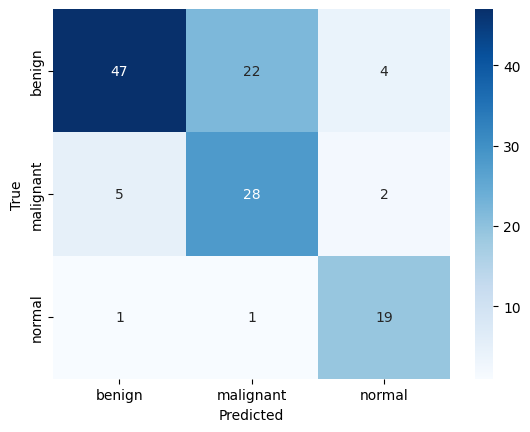

In [6]:
y_prob = model.predict(test_ds, verbose=0)
y_prob = y_prob / y_prob.sum(1, keepdims=True)
y_pred = y_prob.argmax(1)
y_true = test_df.y.values
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

def clf_metrics(idx):
    return [accuracy_score(y_true[idx], y_pred[idx]),
            f1_score(y_true[idx], y_pred[idx], average="macro"),
            roc_auc_score(y_true[idx], y_prob[idx], multi_class="ovr", average="macro")]

pt = clf_metrics(np.arange(len(y_true)))
rng_c = np.random.RandomState(SEED)
bs = []
for _ in range(N_BOOT):
    idx = rng_c.randint(0, len(y_true), len(y_true))
    if len(np.unique(y_true[idx])) == len(CLASSES):
        bs.append(clf_metrics(idx))
bs = np.array(bs)
clf_table = pd.DataFrame({"metric": ["accuracy", "macro-F1", "macro OvR AUC"], "value": pt,
                          "ci_low": np.percentile(bs, 2.5, axis=0), "ci_high": np.percentile(bs, 97.5, axis=0)}).round(4)
print(clf_table.to_string(index=False))
clf_table.to_csv(f"{OUT}_classification.csv", index=False)

sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

## Explainers
All gradient-based methods explain the **logit** of the target class (the predicted class), which avoids vanishing gradients when the softmax saturates. Faithfulness metrics below still measure the change in **probability**. RISE masks fade pixels towards the same neutral gray used by the faithfulness metrics.

In [7]:
def minmax(a):
    a = a - a.min()
    return a / (a.max() + 1e-8)

def make_rise_masks(N, s=7, p1=0.5, seed=SEED):
    rng = np.random.RandomState(seed)
    cell = int(np.ceil(IMG_SIZE / s)); up = (s + 1) * cell
    grid = (rng.rand(N, s, s) < p1).astype("float32")
    masks = np.empty((N, IMG_SIZE, IMG_SIZE), "float32")
    for i in range(N):
        m = cv2.resize(grid[i], (up, up), interpolation=cv2.INTER_LINEAR)
        dx, dy = rng.randint(0, cell, 2)
        masks[i] = m[dx:dx + IMG_SIZE, dy:dy + IMG_SIZE]
    return masks

# data-independent baselines
def random_map(x, cls=None):
    return minmax(cv2.GaussianBlur(np.random.rand(IMG_SIZE, IMG_SIZE).astype("float32"), (0, 0), 15))

_yy, _xx = np.mgrid[:IMG_SIZE, :IMG_SIZE]
CENTER = minmax(np.exp(-((_yy - IMG_SIZE / 2) ** 2 + (_xx - IMG_SIZE / 2) ** 2)
                       / (2 * (IMG_SIZE / 4) ** 2)).astype("float32"))
def center_prior(x, cls=None):
    return CENTER

def make_explainers(m, rise_masks=None):
    """Build all explainers for model m (so the same code can explain randomized copies)."""
    conv_t = m.get_layer(CFG["last_conv"]).output
    logit_t = m.get_layer("logits").output
    gm = models.Model(m.input, [conv_t, logit_t])
    lm = models.Model(m.input, logit_t)

    def _cls(x, cls):
        return int(np.argmax(m(x, training=False)[0])) if cls is None else cls

    def _acts_grads(x, cls):
        with tf.GradientTape() as tape:
            conv, lg = gm(x, training=False)
            score = lg[:, cls]
        g = tape.gradient(score, conv)
        return conv[0].numpy(), g[0].numpy()                      # (h, w, c) each

    def _finish(cam):
        return minmax(cv2.resize(cam.astype("float32"), (IMG_SIZE, IMG_SIZE)))

    def gradcam(x, cls=None):
        cls = _cls(x, cls); A, G = _acts_grads(x, cls)
        return _finish(np.maximum((A * G.mean((0, 1))).sum(-1), 0))

    def gradcampp(x, cls=None):
        cls = _cls(x, cls); A, G = _acts_grads(x, cls)
        g2, g3 = G ** 2, G ** 3
        den = 2 * g2 + A.sum((0, 1), keepdims=True) * g3
        alpha = g2 / np.where(den != 0, den, 1.0)
        w = (alpha * np.maximum(G, 0)).sum((0, 1))
        return _finish(np.maximum((A * w).sum(-1), 0))

    def layercam(x, cls=None):
        cls = _cls(x, cls); A, G = _acts_grads(x, cls)
        return _finish(np.maximum((np.maximum(G, 0) * A).sum(-1), 0))

    def integrated_gradients(x, cls=None, steps=32):
        cls = _cls(x, cls)
        x = tf.convert_to_tensor(x, tf.float32)
        baseline = tf.constant(GRAY[None], tf.float32)           # neutral gray (model-input space)
        alphas = tf.linspace(0.0, 1.0, steps + 1)[:, None, None, None]
        inter = baseline + alphas * (x - baseline)
        with tf.GradientTape() as tape:
            tape.watch(inter)
            p = lm(inter, training=False)[:, cls]
        g = tape.gradient(p, inter)
        avg = tf.reduce_mean((g[:-1] + g[1:]) / 2.0, axis=0, keepdims=True)   # trapezoid rule
        attr = tf.reduce_sum(tf.abs(((x - baseline) * avg)[0]), axis=-1).numpy()
        return minmax(cv2.GaussianBlur(attr, (0, 0), 2))

    def rise(x, cls=None):
        cls = _cls(x, cls)
        x0 = np.asarray(x)[0]
        preds = []
        for i in range(0, len(rise_masks), 100):
            mk = rise_masks[i:i + 100, ..., None]
            preds.append(m.predict(GRAY + (x0 - GRAY) * mk, batch_size=100, verbose=0)[:, cls])
        preds = np.concatenate(preds)
        sal = np.tensordot(preds, rise_masks, axes=(0, 0)) / (rise_masks.sum(0) + 1e-8)
        return minmax(sal.astype("float32"))

    ex = {"Grad-CAM": gradcam, "Grad-CAM++": gradcampp, "LayerCAM": layercam,
          "Integrated Gradients": integrated_gradients}
    if rise_masks is not None:
        ex["RISE"] = rise
    ex["Random (baseline)"] = random_map
    ex["Center prior (baseline)"] = center_prior
    return ex

rise_masks = make_rise_masks(N_RISE) if USE_RISE else None
EXPLAINERS = make_explainers(model, rise_masks)
print(list(EXPLAINERS))

['Grad-CAM', 'Grad-CAM++', 'LayerCAM', 'Integrated Gradients', 'RISE', 'Random (baseline)', 'Center prior (baseline)']


## Metrics

In [8]:
def predict_cls_prob(imgs, cls):
    return model.predict(imgs, batch_size=32, verbose=0)[:, cls]

def deletion_insertion(x, cam, cls, steps=20):
    """x: (224,224,3) preprocessed. Returns (deletion_auc, insertion_auc, curves)."""
    order = np.argsort(-cam.ravel())
    n = cam.size
    blur = cv2.GaussianBlur(x, (0, 0), 10)
    fr = np.linspace(0, 1, steps + 1)
    del_imgs, ins_imgs = [], []
    for f in fr:
        mask = np.zeros(n, bool); mask[order[:int(f * n)]] = True
        mask = mask.reshape(IMG_SIZE, IMG_SIZE, 1)
        del_imgs.append(np.where(mask, GRAY, x))     # remove most relevant pixels -> neutral gray
        ins_imgs.append(np.where(mask, x, blur))     # reveal most relevant pixels on blurred image
    pd_ = predict_cls_prob(np.stack(del_imgs), cls)
    pi_ = predict_cls_prob(np.stack(ins_imgs), cls)
    return auc(fr, pd_), auc(fr, pi_), (fr, pd_, pi_)

def drop_and_increase(x, cam, cls):
    """Average Drop & Increase-in-Confidence: explanation-masked image vs. original."""
    y = predict_cls_prob(x[None], cls)[0]
    o = predict_cls_prob((GRAY + (x - GRAY) * cam[..., None])[None], cls)[0]   # fade low-relevance pixels to gray
    return max(0.0, y - o) / (y + 1e-8) * 100, float(o > y) * 100

def lesion_mask(paths):
    """Union of all mask files of an image ("|"-separated); all zeros for normal images."""
    m = np.zeros((IMG_SIZE, IMG_SIZE), np.float32)
    for p in str(paths).split("|"):
        if p:
            mm = cv2.resize(cv2.imread(p, 0), (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
            m = np.maximum(m, (mm > 127).astype(np.float32))
    return m

def localization(cam, mask):
    """Returns energy, relative energy (1 = chance), rank acc, pointing, IoU@0.5, map AUROC (0.5 = chance)."""
    area = mask.mean()
    energy = (cam * mask).sum() / (cam.sum() + 1e-8)                      # relevance mass inside lesion
    K = int(mask.sum())
    top = np.argsort(-cam.ravel())[:K]
    rank_acc = mask.ravel()[top].mean()                                   # top-K pixels inside lesion
    pointing = float(mask.ravel()[np.argmax(cam.ravel())] > 0)            # max point inside lesion
    binm = cam > 0.5
    iou = (binm & (mask > 0)).sum() / ((binm | (mask > 0)).sum() + 1e-8)
    map_auc = roc_auc_score(mask.ravel() > 0, cam.ravel()) if 0 < K < mask.size else np.nan
    return energy, energy / area, rank_acc, pointing, iou, map_auc

def stability(explainer, x, cls, base_cam, n=N_NOISE, sigma=5.0):
    """Mean Spearman correlation between the map and maps from noisy inputs
    (Gaussian noise with sigma=5 on the raw 0-255 pixel scale). Noisy copies that change the
    predicted class are skipped. Returns (mean correlation, fraction of copies kept)."""
    rs = []
    for _ in range(n):
        xn = x + (np.random.normal(0, sigma, x.shape) * SCALE).astype("float32")
        if int(np.argmax(model(xn[None], training=False)[0])) != cls:
            continue
        c2 = explainer(xn[None], cls)
        rs.append(spearmanr(base_cam.ravel(), c2.ravel())[0])
    kept = len(rs) / n                                  # fraction of noisy copies with unchanged prediction
    return (np.nanmean(rs) if rs else np.nan), kept

## Run the evaluation

In [9]:
if N_EVAL_PER_CLASS is None:
    eval_df = test_df.copy()
else:
    eval_df = pd.concat([g.sample(min(len(g), N_EVAL_PER_CLASS), random_state=SEED)
                         for _, g in test_df.groupby("label")]).reset_index(drop=True)
eval_df["img_id"] = np.arange(len(eval_df))
print(len(eval_df), "images;", eval_df.label.value_counts().to_dict())

records, curves = [], {k: {"del": [], "ins": []} for k in EXPLAINERS}
t0 = time.time()
for i, r in eval_df.iterrows():
    x = preprocess_input(load_img(r["path"]).numpy())
    cls = int(np.argmax(model(x[None], training=False)[0]))
    mask = lesion_mask(r["mask_path"])
    has_lesion = mask.sum() > 0
    for name, fn in EXPLAINERS.items():
        cam = fn(x[None], cls)
        d_auc, i_auc, (fr, pdel, pins) = deletion_insertion(x, cam, cls)
        avg_drop, inc_conf = drop_and_increase(x, cam, cls)
        if has_lesion:
            energy, rel_energy, rank_acc, pointing, iou, map_auc = localization(cam, mask)
        else:                                  # normal image: no lesion -> localization undefined
            energy = rel_energy = rank_acc = pointing = iou = map_auc = np.nan
        stab, stab_kept = stability(fn, x, cls, cam)
        curves[name]["del"].append(pdel); curves[name]["ins"].append(pins)
        records.append(dict(img_id=r.img_id, method=name, true=r.label, pred=CLASSES[cls],
                            correct=bool(cls == r.y),
                            deletion_auc=d_auc, insertion_auc=i_auc, avg_drop=avg_drop, inc_conf=inc_conf,
                            lesion_energy=energy, rel_energy=rel_energy, rank_acc=rank_acc,
                            pointing=pointing, iou=iou, map_auc=map_auc,
                            stability=stab, stab_kept=stab_kept, lesion_area_frac=mask.mean(),
                            group=r.group))
    if (i + 1) % 10 == 0:
        print(f"{i+1}/{len(eval_df)} images done ({time.time()-t0:.0f}s)")

res = pd.DataFrame(records)
res.to_csv(f"{OUT}_per_image.csv", index=False)

129 images; {'benign': 73, 'malignant': 35, 'normal': 21}
10/129 images done (503s)
20/129 images done (934s)
30/129 images done (1365s)
40/129 images done (1785s)
50/129 images done (2247s)
60/129 images done (2700s)
70/129 images done (3166s)
80/129 images done (3634s)
90/129 images done (4109s)
100/129 images done (4560s)
110/129 images done (5006s)
120/129 images done (5485s)


## Results with bootstrap confidence intervals

In [10]:
metric_cols = ["deletion_auc", "insertion_auc", "avg_drop", "inc_conf",
               "lesion_energy", "rel_energy", "rank_acc", "pointing", "iou", "map_auc", "stability"]
LOWER_BETTER = {"deletion_auc", "avg_drop"}
METHODS = list(res.method.unique())
rng_b = np.random.RandomState(SEED)

def boot_ci(v, g, n=N_BOOT):
    """Cluster bootstrap: resamples duplicate GROUPS (not single images), because near-duplicate
    images in the test set are not independent. Mean = mean over all images in resampled groups."""
    v = np.asarray(v, float); g = np.asarray(g)
    ok = ~np.isnan(v); v, g = v[ok], g[ok]
    if len(v) == 0:
        return np.nan, np.nan, np.nan, 0
    _, inv = np.unique(g, return_inverse=True)
    s = np.bincount(inv, weights=v); c = np.bincount(inv).astype(float)
    idx = rng_b.randint(0, len(s), (n, len(s)))
    bm = s[idx].sum(1) / c[idx].sum(1)
    lo, hi = np.percentile(bm, [2.5, 97.5])
    return v.mean(), lo, hi, len(v)

num_rows = []
for mth in METHODS:
    sub = res[res.method == mth]
    for mc in metric_cols:
        mean, lo, hi, n = boot_ci(sub[mc], sub["group"])
        num_rows.append(dict(method=mth, metric=mc, mean=mean, ci_low=lo, ci_high=hi, n=n))
ci_df = pd.DataFrame(num_rows)
ci_df.round(4).to_csv(f"{OUT}_summary_ci.csv", index=False)

pretty = ci_df.assign(txt=lambda d: d.apply(lambda r: f"{r['mean']:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)) \
              .pivot(index="metric", columns="method", values="txt").loc[metric_cols, METHODS]
print("=== Mean [95% bootstrap CI]  (localization metrics: benign/malignant images only) ===")
print(pretty.to_string())

lesion_rows = res[res.lesion_area_frac > 0]
print("\nChance levels -> lesion_energy / rank_acc / pointing ~", round(lesion_rows.lesion_area_frac.mean(), 3),
      "| rel_energy = 1 | map_auc = 0.5")
print("Stability: mean fraction of noisy copies kept (prediction unchanged):",
      res.groupby("method").stab_kept.mean().round(3).to_dict())
print("Better = LOWER for:", sorted(LOWER_BETTER), "| HIGHER for all other metrics")

print("\n=== Per true class (mean) ===")
per_class = res.groupby(["method", "true"])[metric_cols].mean().round(4)
print(per_class); per_class.to_csv(f"{OUT}_per_class.csv")

print("\n=== Correct vs incorrect predictions (mean) ===")
per_corr = res.groupby(["method", "correct"])[metric_cols].mean().round(4)
print(per_corr); per_corr.to_csv(f"{OUT}_correct_vs_incorrect.csv")
print("\n#correctly / incorrectly classified eval images:",
      res.drop_duplicates("img_id").correct.value_counts().to_dict())

=== Mean [95% bootstrap CI]  (localization metrics: benign/malignant images only) ===
method                        Grad-CAM               Grad-CAM++                 LayerCAM     Integrated Gradients                     RISE        Random (baseline)  Center prior (baseline)
metric                                                                                                                                                                                      
deletion_auc      0.404 [0.360, 0.446]     0.439 [0.393, 0.486]     0.439 [0.391, 0.486]     0.457 [0.416, 0.496]     0.394 [0.342, 0.450]     0.455 [0.396, 0.516]     0.434 [0.368, 0.498]
insertion_auc     0.644 [0.598, 0.693]     0.634 [0.589, 0.680]     0.634 [0.590, 0.676]     0.583 [0.531, 0.634]     0.640 [0.585, 0.692]     0.517 [0.469, 0.563]     0.565 [0.512, 0.616]
avg_drop       21.919 [16.855, 27.503]  24.910 [19.791, 30.348]  24.891 [19.460, 30.423]  25.957 [21.683, 30.520]     2.095 [1.121, 3.158]  22.033 [17.574, 26

In [11]:
# Paired Wilcoxon signed-rank tests (per image), Holm-corrected within each (metric, reference) family
def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); mm = len(p)
    adj = np.empty(mm); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (mm - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

def paired_table(metric, refs=("Random (baseline)", "Grad-CAM")):
    wide = res.pivot(index="img_id", columns="method", values=metric)
    out = []
    for ref in refs:
        if ref not in wide.columns:
            continue
        names, ps, diffs = [], [], []
        for mth in wide.columns:
            if mth == ref:
                continue
            d = wide[[mth, ref]].dropna()
            diff = d[mth] - d[ref]
            p = 1.0 if (len(d) < 5 or np.allclose(diff, 0)) else wilcoxon(d[mth], d[ref]).pvalue
            names.append(mth); ps.append(p); diffs.append(diff.mean())
        for mth, dfm, pa in zip(names, diffs, holm(ps)):
            out.append(dict(metric=metric, method=mth, vs=ref, mean_diff=dfm, p_holm=pa))
    return pd.DataFrame(out)

tests = pd.concat([paired_table(mc) for mc in metric_cols], ignore_index=True)
tests["sig(p<0.05)"] = tests.p_holm < 0.05
tests.round(4).to_csv(f"{OUT}_paired_tests.csv", index=False)
key = ["deletion_auc", "insertion_auc", "rel_energy", "map_auc", "pointing", "stability"]
print(tests[tests.metric.isin(key)].round(4).to_string(index=False))
print("mean_diff = method minus reference (for deletion_auc / avg_drop a NEGATIVE difference is better)")

       metric                  method                vs  mean_diff  p_holm  sig(p<0.05)
 deletion_auc Center prior (baseline) Random (baseline)    -0.0209  0.0605        False
 deletion_auc                Grad-CAM Random (baseline)    -0.0506  0.0402         True
 deletion_auc              Grad-CAM++ Random (baseline)    -0.0158  1.0000        False
 deletion_auc    Integrated Gradients Random (baseline)     0.0021  1.0000        False
 deletion_auc                LayerCAM Random (baseline)    -0.0155  1.0000        False
 deletion_auc                    RISE Random (baseline)    -0.0602  0.0000         True
 deletion_auc Center prior (baseline)          Grad-CAM     0.0297  0.3737        False
 deletion_auc              Grad-CAM++          Grad-CAM     0.0348  0.0000         True
 deletion_auc    Integrated Gradients          Grad-CAM     0.0527  0.0001         True
 deletion_auc                LayerCAM          Grad-CAM     0.0351  0.0000         True
 deletion_auc                   

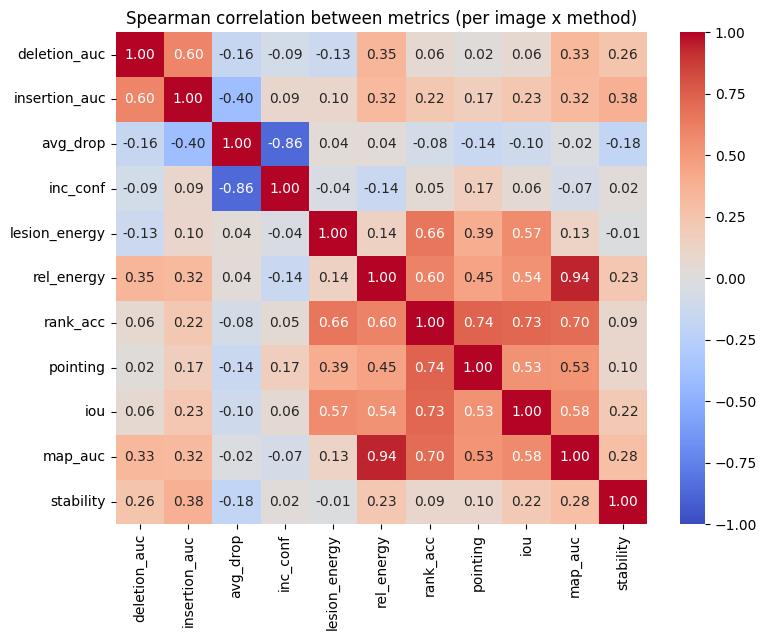

=== Method rank per metric (1 = best) ===
                         deletion_auc  insertion_auc  avg_drop  inc_conf  lesion_energy  rel_energy  rank_acc  pointing  iou  map_auc  stability
method                                                                                                                                          
Grad-CAM                            2              1         2         3              2           2         3         3    1        4          6
Grad-CAM++                          4              4         5         5              4           4         5         4    3        2          3
LayerCAM                            5              3         4         4              3           3         4         4    2        1          2
Integrated Gradients                7              5         6         6              1           1         1         1    6        3          5
RISE                                1              2         1         1              6 

In [12]:
# Do the metrics agree? (real explainers only; baselines excluded)
real = res[~res.method.str.contains("baseline")]
corr = real[metric_cols].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation between metrics (per image x method)")
plt.tight_layout(); plt.savefig(f"{OUT}_metric_agreement.png", dpi=200); plt.show()

# Method ranking per metric (1 = best)
means = res.groupby("method")[metric_cols].mean().loc[METHODS]
ranks = pd.DataFrame({mc: means[mc].rank(ascending=(mc in LOWER_BETTER)) for mc in metric_cols})
print("=== Method rank per metric (1 = best) ===")
print(ranks.astype(int).to_string())
ranks.to_csv(f"{OUT}_method_ranks.csv")

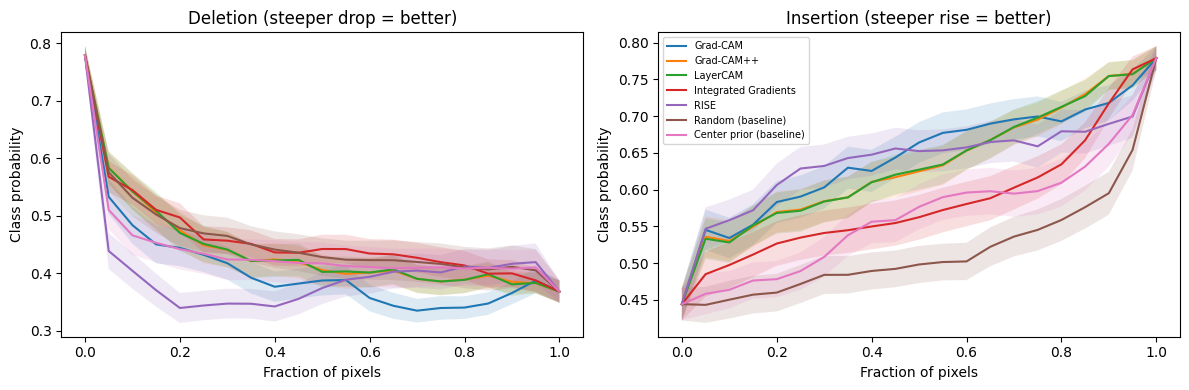

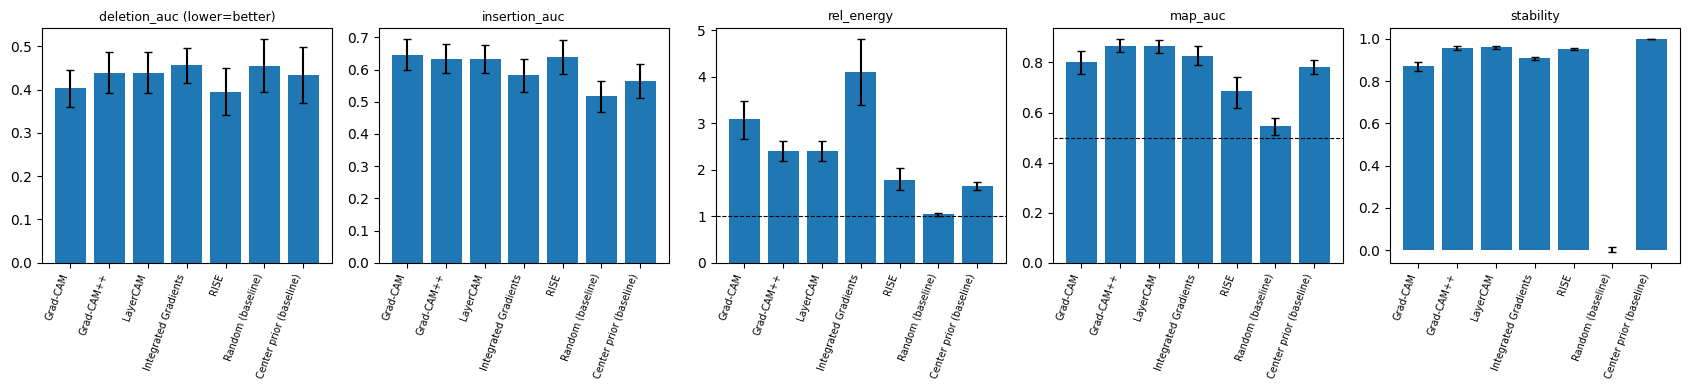

In [13]:
fr = np.linspace(0, 1, 21)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in EXPLAINERS:
    for k, a in zip(["del", "ins"], ax):
        arr = np.array(curves[name][k]); mu = arr.mean(0)
        a.plot(fr, mu, label=name)
        a.fill_between(fr, mu - arr.std(0) / np.sqrt(len(arr)), mu + arr.std(0) / np.sqrt(len(arr)), alpha=0.15)
ax[0].set_title("Deletion (steeper drop = better)"); ax[1].set_title("Insertion (steeper rise = better)")
for a in ax:
    a.set_xlabel("Fraction of pixels"); a.set_ylabel("Class probability")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT}_deletion_insertion_curves.png", dpi=200); plt.show()

# Bar chart of key metrics with 95% CIs
plot_m = ["deletion_auc", "insertion_auc", "rel_energy", "map_auc", "stability"]
fig, axs = plt.subplots(1, len(plot_m), figsize=(3.4 * len(plot_m), 4), sharey=False)
for a, mc in zip(axs, plot_m):
    s = ci_df[ci_df.metric == mc].set_index("method").loc[METHODS]
    a.bar(range(len(METHODS)), s["mean"], yerr=[s["mean"] - s.ci_low, s.ci_high - s["mean"]], capsize=3)
    a.set_xticks(range(len(METHODS))); a.set_xticklabels(METHODS, rotation=70, ha="right", fontsize=7)
    a.set_title(mc + (" (lower=better)" if mc in LOWER_BETTER else ""), fontsize=9)
    if mc == "rel_energy": a.axhline(1, ls="--", c="k", lw=0.8)
    if mc == "map_auc": a.axhline(0.5, ls="--", c="k", lw=0.8)
plt.tight_layout(); plt.savefig(f"{OUT}_key_metrics_ci.png", dpi=200); plt.show()

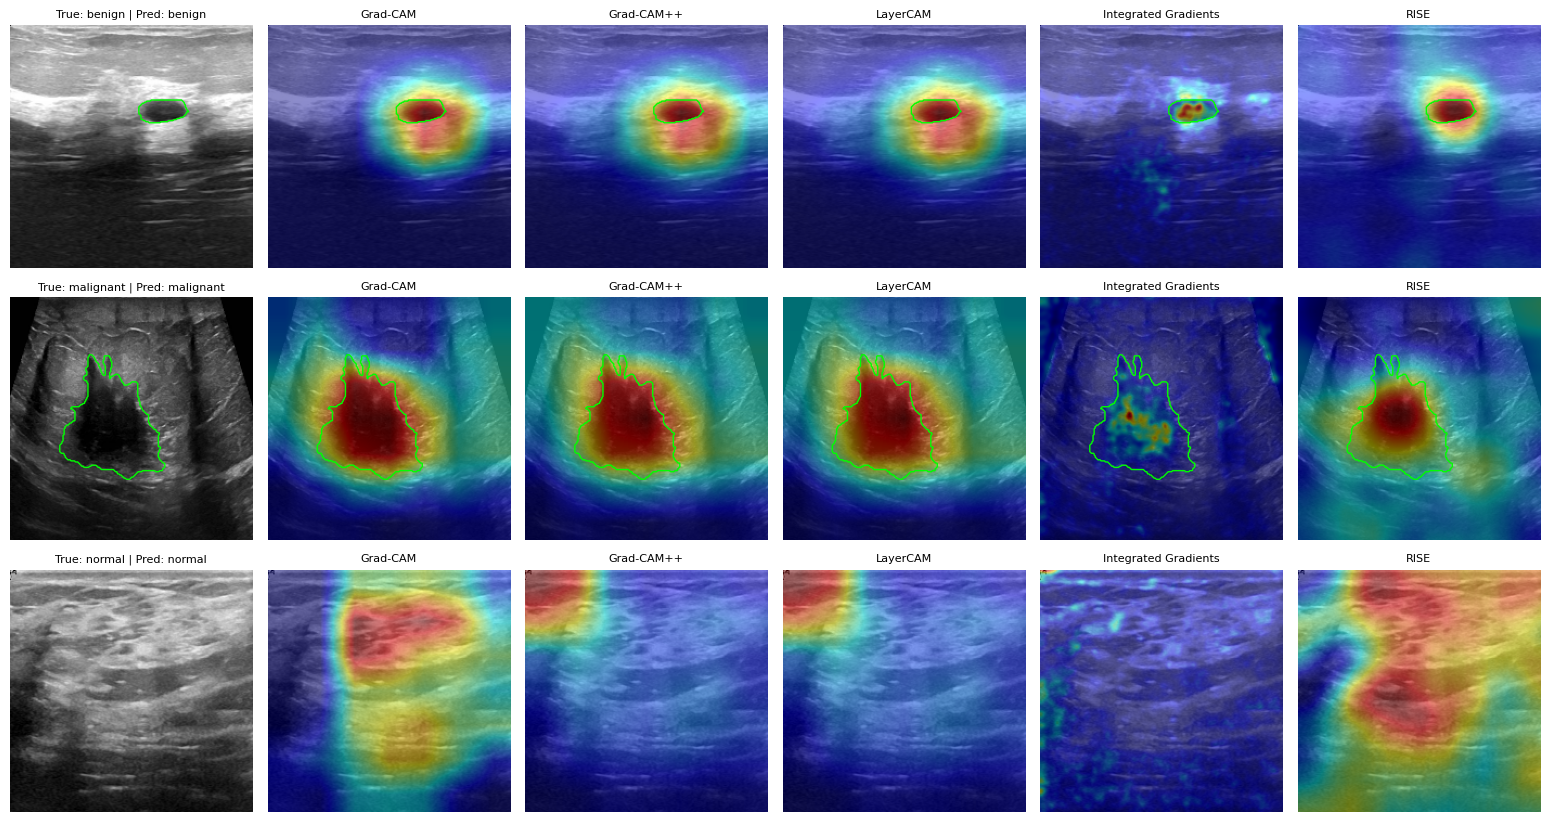

In [14]:
# Qualitative examples: one image per true class (green contour = lesion mask)
show = [m_ for m_ in EXPLAINERS if "baseline" not in m_]
fig, axs = plt.subplots(len(CLASSES), len(show) + 1, figsize=(2.6 * (len(show) + 1), 2.8 * len(CLASSES)))
for row, c in enumerate(CLASSES):
    r = eval_df[eval_df["label"] == c].iloc[0]
    raw = load_img(r["path"]).numpy().astype("uint8")
    x = preprocess_input(load_img(r["path"]).numpy())
    cls = int(np.argmax(model(x[None], training=False)[0]))
    mk = lesion_mask(r["mask_path"])
    panels = [("True: %s | Pred: %s" % (c, CLASSES[cls]), raw)]
    for name in show:
        m_ = EXPLAINERS[name](x[None], cls)
        heat = cv2.applyColorMap((m_ * 255).astype("uint8"), cv2.COLORMAP_JET)[..., ::-1]
        panels.append((name, (0.55 * raw + 0.45 * heat).astype("uint8")))
    for a, (t, im) in zip(axs[row], panels):
        a.imshow(im); a.set_title(t, fontsize=8); a.axis("off")
        if mk.max() > 0:
            a.contour(mk, levels=[0.5], colors="lime", linewidths=1)
plt.tight_layout(); plt.savefig(f"{OUT}_qualitative.png", dpi=200); plt.show()

## Sanity check: model-parameter randomization
If an explanation really depends on what the model learned, re-initializing the weights must destroy it. We compare the map of the trained model with the map of (a) a model whose classifier head is re-initialized and (b) a fully re-initialized model, for the **same target class**. Spearman correlation close to 0 means the method passes. A method that stays highly correlated is acting like an edge or image detector rather than a model explanation.

In [15]:
sanity_pool = eval_df[eval_df.label != "normal"]
sanity_df = sanity_pool.sample(min(N_SANITY, len(sanity_pool)), random_state=SEED)

fresh = models.clone_model(model)                         # same architecture, random weights
base_names = {l.name for l in base.layers}
head_rand = models.clone_model(model)
head_rand.set_weights(model.get_weights())
for l in model.layers:
    if l.name not in base_names and l.weights:
        head_rand.get_layer(l.name).set_weights(fresh.get_layer(l.name).get_weights())

variants = {"head re-initialized": make_explainers(head_rand, rise_masks),
            "all weights re-initialized": make_explainers(fresh, rise_masks)}
real_methods = [k for k in EXPLAINERS if "baseline" not in k]
srows = []
for _, r in sanity_df.iterrows():
    x = preprocess_input(load_img(r["path"]).numpy())
    cls = int(np.argmax(model(x[None], training=False)[0]))
    for mth in real_methods:
        ref = EXPLAINERS[mth](x[None], cls)
        for vname, ex in variants.items():
            rho = spearmanr(ref.ravel(), ex[mth](x[None], cls).ravel())[0]
            srows.append(dict(method=mth, variant=vname, rho=rho))
sanity = pd.DataFrame(srows)
sanity_tab = sanity.groupby(["method", "variant"]).rho.agg(["mean", "std"]).round(3).unstack("variant")
print(sanity_tab.to_string())
sanity_tab.to_csv(f"{OUT}_sanity_randomization.csv")

                                           mean                                            std                    
variant              all weights re-initialized head re-initialized all weights re-initialized head re-initialized
method                                                                                                            
Grad-CAM                                  0.129               0.367                      0.262               0.378
Grad-CAM++                                0.246               0.975                      0.407               0.025
Integrated Gradients                      0.631               0.818                      0.089               0.090
LayerCAM                                  0.245               0.974                      0.407               0.026
RISE                                     -0.246               0.264                      0.275               0.316


## Compare backbones
Run the notebook once per value of `BACKBONE` (the output files carry the backbone name). This cell then merges every `xai_*_per_image.csv` found in the working directory.

In [16]:
files = sorted(glob.glob("xai_*_per_image.csv"))
if len(files) > 1:
    allres = pd.concat([pd.read_csv(f).assign(backbone=f[len("xai_"):-len("_per_image.csv")]) for f in files])
    cmp_tab = allres.groupby(["backbone", "method"])[["deletion_auc", "insertion_auc", "rel_energy",
                                                      "map_auc", "pointing", "stability"]].mean().round(3)
    print(cmp_tab.to_string()); cmp_tab.to_csv("xai_backbone_comparison.csv")
else:
    print("Only one backbone found so far:", files)

Only one backbone found so far: ['xai_resnet50_per_image.csv']
